# Laboratoire de programmation mathématique 6 : <br/>Comptage par fonctions génératrices <span style="color:silver">(combinatoire + une excursion en bioinformatique)</span>

## La voie de la grenouille

Une grenouille part de la position 0 et peut sauter de 1, 2 ou 3 pas en avant. De combien de façons peut-elle atteindre la position $n$ ?

Pour $n=4$, nous avons ces options :
$$0\xrightarrow{1}1\xrightarrow{1}2\xrightarrow{1}3\xrightarrow{1}4$$ 
$$0\xrightarrow{2}2\xrightarrow{1}3\xrightarrow{1}4$$ 
$$0\xrightarrow{1}1\xrightarrow{2}3\xrightarrow{1}4$$
$$0\xrightarrow{1}1\xrightarrow{1}2\xrightarrow{2}4$$
$$0\xrightarrow{2}2\xrightarrow{2}4$$
$$0\xrightarrow{1}1\xrightarrow{3}4$$
$$0\xrightarrow{3}3\xrightarrow{1}4$$
soit un total de 7 façons.

Comment pouvons-nous le calculer ? Soit $f(n)$ le nombre de façons d'arriver à $n$. La position finale de la grenouille est $n$, et selon la longueur de son dernier saut, sa position précédente était $n-1$, $n-2$, ou $n-3$. Nous obtenons ainsi (pour tout $n\geq 1$)
$$f(n) = f(n-1) + f(n-2) + f(n-3)$$
avec la « condition initiale » $f(0)=1$, $f(-1)=f(-2)=0$ (la grenouille n'est jamais à une position strictement négative).

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Écrivez une fonction Python `frog(n)` qui calcule $f(n)$. Faites-le à l'aide d'une boucle `for`, en calculant successivement $f(1)$, $f(2)$, ..., $f(n)$ (et en mémorisant les 3 valeurs précédentes, afin de pouvoir appliquer la formule pour $f(n)$).
</div>



In [1]:
### ÉCRIVEZ ICI

def frog(n):
    fm2 = 0
    fm1 = 0
    f0 = 1
    
    for _ in range(n):
        current = fm2 + fm1 + f0
        fm2 = fm1
        fm1 = f0
        f0 = current
        
    return f0

print(f"Pour n = 4, le nombre de façons est : {frog(4)}")

Pour n = 4, le nombre de façons est : 7


In [2]:
### EXÉCUTEZ-MOI -- TEST

assert (res:=frog(100)) == (correct:=180396380815100901214157639), f"attendu : {correct}, obtenu : {res}"
print("OK !")

OK !


### Et la récursivité ?

Dans l'exercice précédent, vous avez calculé $f(n)$ avec une boucle `for`. Pouvons-nous demander à Python de calculer $f(n)$ directement en utilisant la relation $f(n) = f(n-1) + f(n-2) + f(n-3)$ et les conditions initiales $f(0)=1$ et $f(n)=0$ pour $n<0$ ? La fonction ci-dessous fait exactement cela (c'est une fonction _récursive_, car elle s'appelle elle-même). Elle contient également une commande `print`, pour vous montrer quand elle s'exécute. Lisez et exécutez les deux cellules ci-dessous.


In [3]:
### EXÉCUTEZ-MOI

def rfrog(n):
    print(n, end=', ')   # indiquer que la fonction a été appelée
    if n < 0:
        return 0
    if n == 0:
        return 1
    return rfrog(n-1) + rfrog(n-2) + rfrog(n-3)

In [4]:
### EXÉCUTEZ-MOI

rfrog(10)

10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 5, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 6, 5, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 5, 4, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 3, 2, 1, 0, -1, -2, 0, -1, 1, 0, -1, -2, 0, 2, 1, 0, -1, -2, 0, -1, 7, 6, 5, 4, 3,

274

Comme vous pouvez le voir, ce n'était pas très efficace - pour calculer $f(10)$ de cette manière, nous avons dû calculer les $f(n)$ pour des $n$ plus petits de nombreuses fois, alors que la boucle `for` ne l'a fait qu'une seule fois. La fonction est déjà inutile pour calculer $f(30)$ - vous pouvez l'essayer (mais supprimez d'abord la commande `print`, sinon trop de nombres seraient affichés).

Ce serait mieux si la fonction se souvenait : « J'ai déjà calculé $f(5)$, voici le résultat dont je me souviens ». Python peut le faire - il existe un décorateur pour permettre aux fonctions de mémoriser. (L'inconvénient est que cela prend de la mémoire).


In [5]:
### EXÉCUTEZ-MOI

from functools import cache

@cache
def rfrog(n):            # la même fonction qu'avant
    print(n, end=', ')   # indiquer que la fonction a été appelée
    if n < 0:
        return 0
    if n == 0:
        return 1
    return rfrog(n-1) + rfrog(n-2) + rfrog(n-3)

In [6]:
### EXÉCUTEZ-MOI

rfrog(10)

10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0, -1, -2, 

274

In [7]:
### EXÉCUTEZ-MOI

rfrog(20)

20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 

121415

<div style="border: 1px solid gold; padding: 5px">

**Exercice :** (Nombres de Delannoy)

Un roi d'échecs est à la position (0,0). Il ne peut se déplacer que vers la droite, vers le haut, ou en diagonale vers le haut à droite (toujours d'une seule case). De combien de façons peut-il atteindre une position $(m,n)$ ? Écrivez une fonction récursive `rking(m,n)` calculant ce nombre ; n'oubliez pas de la décorer avec `@cache`.

**Bonus :** Écrivez une fonction non récursive `king` en utilisant des boucles `for`. Vous devrez mémoriser certaines valeurs, essayez de ne pas en mémoriser plus que nécessaire. 

>En général, la réimplémentation non récursive d'une fonction récursive (évitant les appels multiples de la fonction avec les mêmes arguments) est appelée _programmation dynamique_ (dynamic programming) et c'est l'une des principales façons de créer des algorithmes.

</div>


In [43]:
### ÉCRIVEZ ICI

@cache
def rking(m, n):
    if m < 0 or n < 0:
        return 0
    if m == 0 and n == 0:
        return 1
    return rking(m-1, n) + rking(m, n-1) + rking(m-1, n-1)


In [44]:
def king(m, n):
    if m < 0 or n < 0:
        return 0
        
    dp = [1] * (n + 1)
    
    for i in range(1, m + 1):
        diag = dp[0]
        for j in range(1, n + 1):
            temp = dp[j]
            dp[j] = dp[j] + dp[j-1] + diag
            diag = temp
            
    return dp[n]

In [10]:
### EXÉCUTEZ-MOI - TEST

assert (res:=rking(10,10)) == (correct:=8097453), f"attendu : {correct}, obtenu : {res}"
print("OK !")

OK !


### Enfin les fonctions génératrices

Revenons à notre fonction de grenouille $f(n)$. Construisons sa _fonction génératrice_
$$F(x) = f(0) + f(1)\,x + f(2)\,x^2 +\dots = \sum_{n=0}^\infty f(n)\,x^n.$$
Pour la calculer, utilisons la relation de récurrence
$$f(n) = f(n-1) + f(n-2) + f(n-3)$$
qui est valide pour tous les $n$ sauf pour $n=0$ : nous posons $f(n)=0$ si $n<0$. Écrivons $F(x)$ sous la forme $F(x) = \sum_{n\in\mathbb Z} f(n)\, x^n$.
Nous avons alors par exemple
$$x^2\, F(x) = \sum_n f(n)\,x^{n+2} = \sum_n f(n-2)\, x^n$$
et donc
$$(x+x^2+x^3)\,F(x)= \sum_n(f(n-1) + f(n-2) + f(n-3))\,x^n = -1 + \sum_n f(n)\,x^n = -1 + F(x)$$
($-1$ vient du fait que pour $n=0$ nous avons l'exception $f(0)-1 = f(-1)+f(-2)+f(-3)$).
De là, nous obtenons le résultat
$$F(x) = \frac1{1-x-x^2-x^3}.$$

Voici comment nous pouvons développer des fonctions en séries entières avec sympy et comment obtenir leurs coefficients.


In [11]:
### EXÉCUTEZ-MOI

import sympy as sp
x = sp.symbols('x')

ser = sp.series(sp.exp(x), n=10)
display(ser)
ser.coeff(x**7)

1 + x + x**2/2 + x**3/6 + x**4/24 + x**5/120 + x**6/720 + x**7/5040 + x**8/40320 + x**9/362880 + O(x**10)

1/5040

<div style="border: 1px solid gold; padding: 5px">

**Exercice :** Développez la fonction génératrice $F(x)$ en série entière jusqu'à $x^{20}$. Vérifiez que le coefficient de $x^{10}$ est égal à `frog(10)`.
</div>

In [ ]:
### ÉCRIVEZ ICI

x = sp.symbols('x')
F = 1 / (1 - x - x**2 - x**3)

ser = sp.series(F, n=21)
display(ser)

coeff_10 = ser.coeff(x**10)
print(coeff_10)

print(coeff_10 == frog(10))

1 + x + 2*x**2 + 4*x**3 + 7*x**4 + 13*x**5 + 24*x**6 + 44*x**7 + 81*x**8 + 149*x**9 + 274*x**10 + 504*x**11 + 927*x**12 + 1705*x**13 + 3136*x**14 + 5768*x**15 + 10609*x**16 + 19513*x**17 + 35890*x**18 + 66012*x**19 + 121415*x**20 + O(x**21)

274
True


### Asymptotiques et formules exactes

Que pouvons-nous tirer de la connaissance explicite de $F$ ? Cela nous donnera une formule explicite (bien qu'un peu compliquée) pour $f(n)$, mais cela expliquera aussi comment $f(n)$ se comporte pour les grands $n$.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :** 

- Écrivez une fonction `lfrog(n)` qui renvoie la liste $[f(0),\dots,f(n)]$. Faites-le en modifiant un peu votre fonction `frog(n)`, en stockant les valeurs intermédiaires dans une liste, puis en renvoyant cette liste.
- Utilisez la fonction pour tracer le graphique de $f$ pour $n\leq 100$, avec une échelle logarithmique sur l'axe des ordonnées ($y$).
</div>


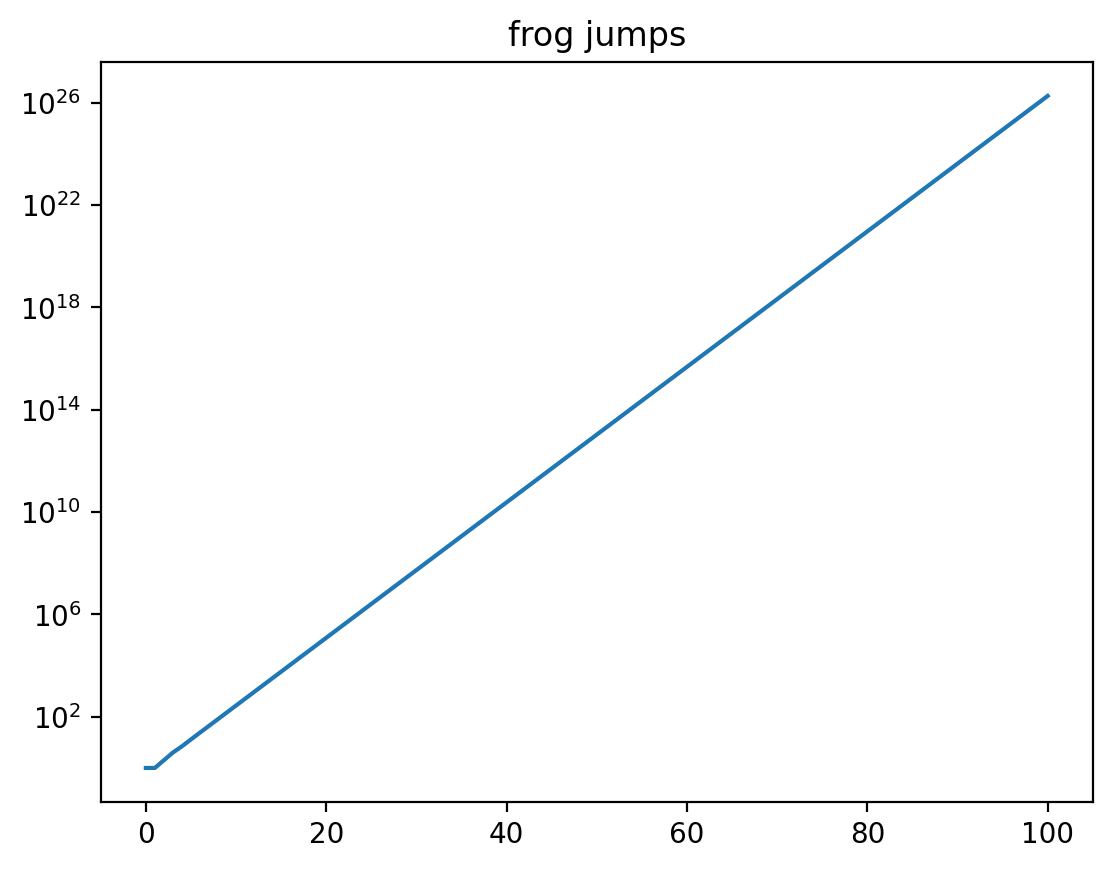

In [14]:
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

### ÉCRIVEZ ICI

def lfrog(n):
    fm2 = 0
    fm1 = 0
    f0 = 1
    result = [f0]
    
    for _ in range(n):
        current = fm2 + fm1 + f0
        fm2 = fm1
        fm1 = f0
        f0 = current
        result.append(f0)
        
    return result

y_vals = lfrog(100)
x_vals = range(101)

plt.semilogy(x_vals, y_vals)
plt.title("frog jumps")
plt.show()

Nous voyons que $f(n)$ croît de manière exponentielle, plus précisément que $f(n)\approx a\,b^n$ pour certains $a,b>0$. Pourquoi, et comment trouver $a$ et $b$ ?

Si nous décomposons $F(x)$ en fractions partielles (éléments simples)
$$F(x)=\frac1{1-x-x^2-x^3} = \frac{a_1}{1-b_1 x} + \frac{a_2}{1-b_2 x} + \frac{a_3}{1-b_3 x}$$
et que nous développons ces fractions comme des séries géométriques, nous obtenons
$$F(x) = \sum_{n=0}^\infty (a_1 b_1^n + a_2 b_2^n + a_3 b_3^n)\,x^n$$
et nous obtenons ainsi la "formule exacte"
$$f(n) = a_1 b_1^n + a_2 b_2^n + a_3 b_3^n$$
Pour les grands $n$, le terme avec le plus grand $b_k$ (en valeur absolue) l'emporte et les deux autres termes deviennent négligeables.

> Cette décomposition en fractions partielles peut vous sembler peu familière. En Analyse (ou ailleurs), vous avez probablement vu une décomposition avec des termes de la forme $\frac{c}{x - r}$, où $r$ est une racine du polynôme au dénominateur ($1-x-x^2-x^3$). Mais c'est la même chose, car $\frac{a}{1-bx} = \frac{-a/b}{x-1/b}$. En particulier, les $1/b_k$ sont les racines de $1-x-x^2-x^3$.
>
> Cependant, pour rendre la relation plus claire, nous pouvons la réécrire différemment : nous avons
> $$\frac a{1-bx} = \frac {at}{t-b}\quad\text{pour}\quad t=1/x$$
> et donc
> $$\frac{a_1}{t-b_1} + \frac{a_2}{t-b_2} + \frac{a_3}{t-b_3} = \frac{F(1/t)}t = \frac{t^2}{t^3-t^2-t-1}$$

<div style="border: 1px solid gold; padding: 5px">

**Exercice :** Exécutez la cellule ci-dessous qui calcule la décomposition en fractions partielles de
$$\frac{t^2}{t^3-t^2-t-1}.$$
Ensuite, calculez $a,b>0$ tels que $f(n)\approx a\,b^n$ via $b = f(20)/f(19)$ et $a = f(20)/b^{20}$. Comparez le résultat avec les fractions partielles que vous avez obtenus.
</div>


In [45]:
### EXÉCUTEZ-MOI

t = sp.symbols('t')

# sp.apart calcule la décomposition en fractions partielles
# doit() effectue le calcul (sympy est "paresseux")
# n() donne les valeurs numériques

sp.apart(t**2/(t**3 - t**2 - t - 1), full=True).doit().n()

(0.190790038840304 + 0.0187005831117398*I)/(t + 0.419643377607081 + 0.606290729207199*I) + (0.190790038840304 - 0.0187005831117398*I)/(t + 0.419643377607081 - 0.606290729207199*I) + 0.618419922319393/(t - 1.83928675521416)

In [16]:
### ÉCRIVEZ ICI

f_19 = frog(19)
f_20 = frog(20)

b = f_20 / f_19
a = f_20 / (b**20)

print(f"a = {a}")
print(f"b = {b}")

a = 0.6184196495108387
b = 1.8392867963400594


### Asymptotiques diagonales du roi

Ci-dessus, vous avez implémenté une fonction `rking(m,n)` calculant le nombre de façons dont un roi d'échecs, se déplaçant uniquement vers le haut, vers la droite ou en diagonale vers le haut à droite, peut aller de $(0,0)$ à $(m,n)$. Notons ces nombres $k(m,n)$ (officiellement, ils sont appelés [nombres de Delannoy](https://fr.wikipedia.org/wiki/Nombre_de_Delannoy) et sont notés $D_{m,n}$). Nous avons pour chaque $(m,n)\neq(0,0)$
$$k(m,n) = k(m-1,n)+k(m,n-1)+k(m-1,n-1)$$
(en suivant si le dernier pas du roi était horizontal, vertical ou diagonal). Pour la fonction génératrice
$$K(x,y) = \sum_{m,n}k(m,n)\,x^my^n$$
cela nous donne
$$(x + y + xy)\, K(x,y) = -1 + K(x,y)$$
(le 1 à droite vient de l'exception $(m,n)=(0,0)$), et donc 
$$K(x,y)=\frac1{1-x-y-xy}.$$

Regardons maintenant les nombres $k(n,n)$.


<div style="border: 1px solid gold; padding: 5px">

**Exercice :**
Tracez les nombres $k(n,n)$ pour $0\leq n < 100$ (en utilisant votre fonction `rking`), avec l'échelle logarithmique sur l'axe $y$. Tracez également le graphique des rapports $k(n+1, n+1)/k(n,n)$, cette fois sans l'échelle logarithmique.
</div>


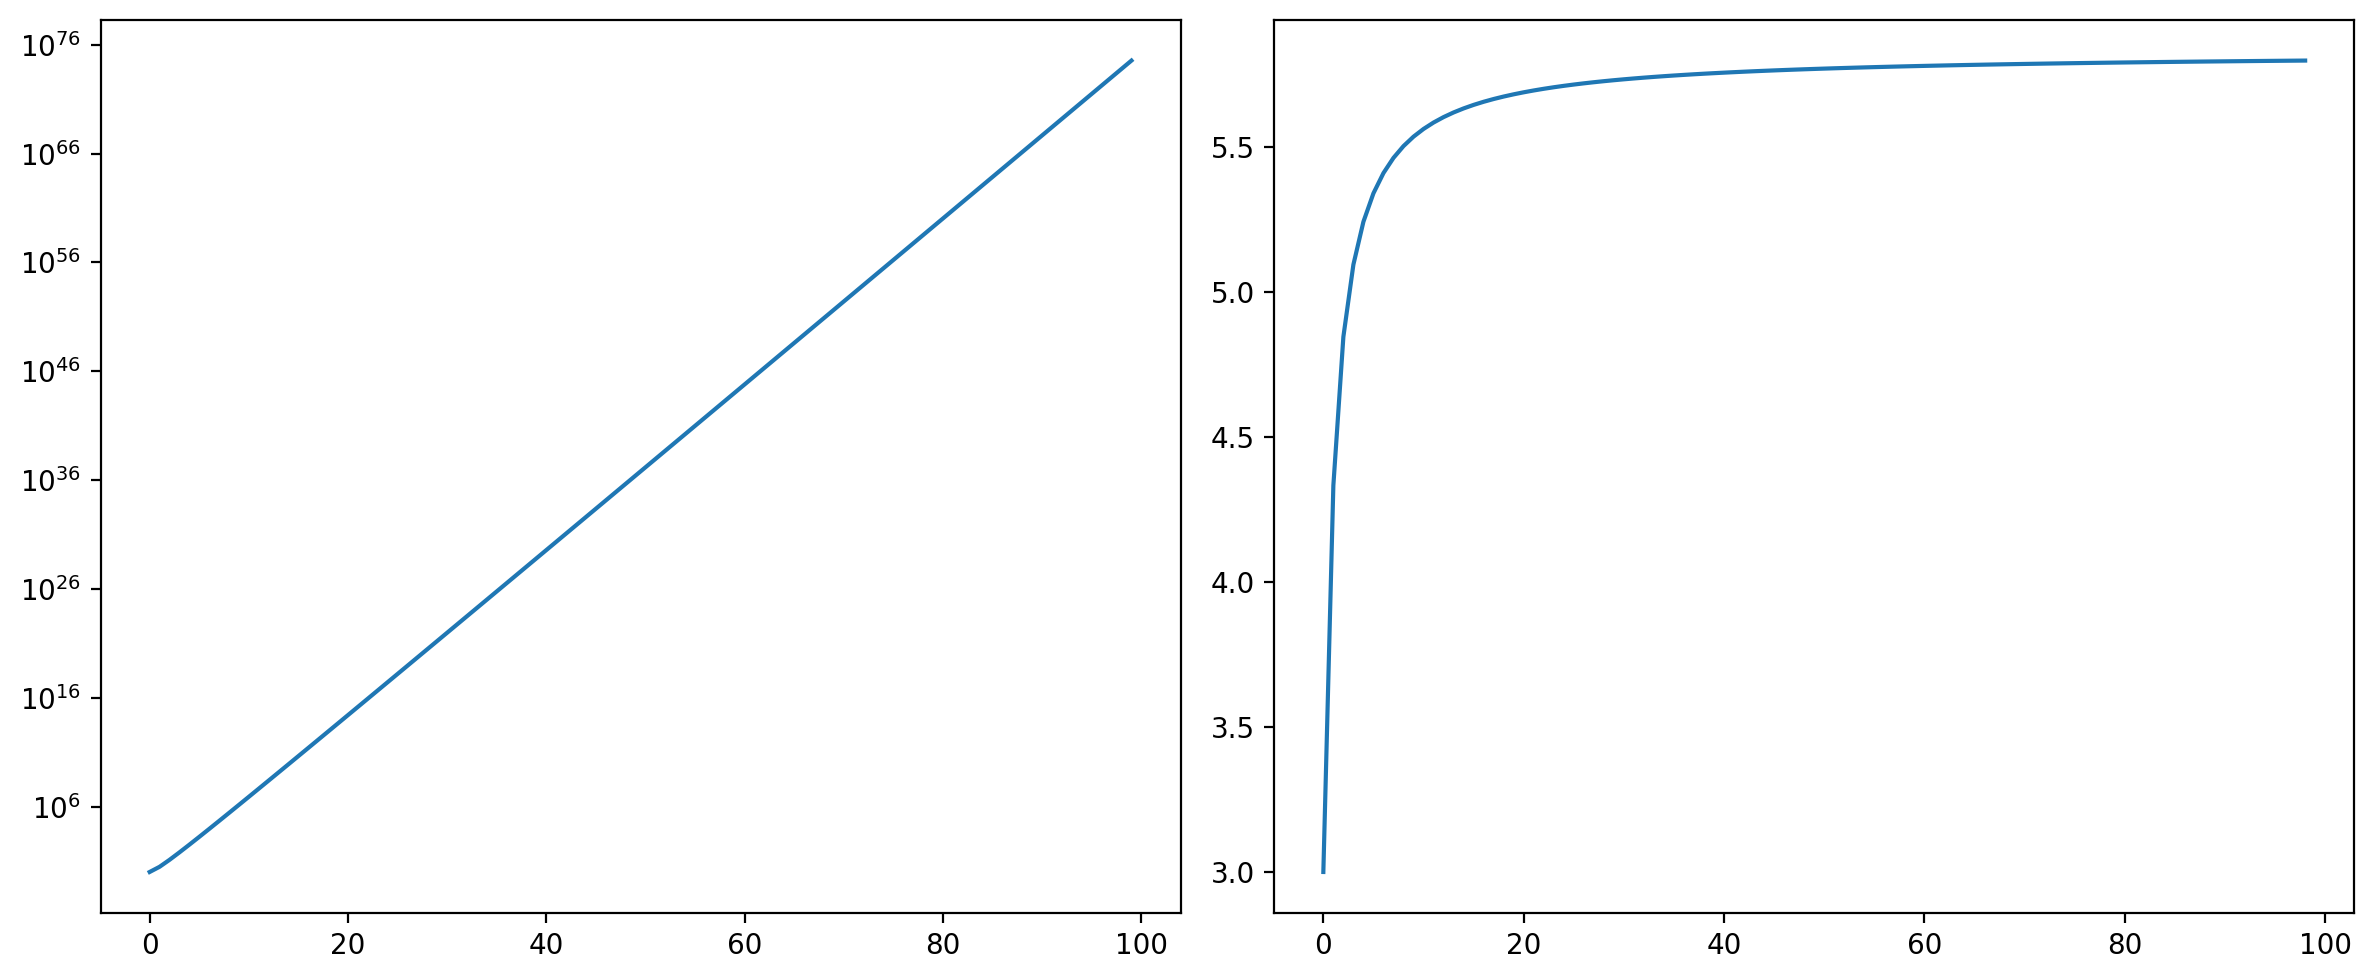

In [46]:
### ÉCRIVEZ ICI

n_vals = range(100)
k_vals = [rking(n, n) for n in n_vals]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.semilogy(n_vals, k_vals)

ratios = [k_vals[i+1] / k_vals[i] for i in range(len(k_vals)-1)]

plt.subplot(1, 2, 2)
plt.plot(n_vals[:-1], ratios)

plt.tight_layout()
plt.show()

Le premier graphique est à nouveau remarquablement proche d'une ligne droite, tandis que le second graphique devient plat pour les grands $n$. Ils indiquent tous deux une croissance exponentielle de $k(n,n)$. Pouvons-nous comprendre le taux de croissance, c'est-à-dire la limite  
$$c = \lim_{n\to\infty}\frac{k(n+1,n+1)}{k(n,n)}\ ?$$

Nous avons besoin de la fonction génératrice
$$K_d(x) = \sum_n k(n,n) x^n$$
de ces nombres « diagonaux » $k(n,n)$. 

> Il n'est pas difficile d'extraire $K_d(x)$ de $K(x,y)$, mais la méthode utilise un concept qui n'était pas encore dans vos cours de mathématiques, à savoir le [théorème des résidus](https://fr.wikipedia.org/wiki/Th%C3%A9or%C3%A8me_des_r%C3%A9sidus) (en Analyse Complexe). Cela donne
> $$K_d(x) = \frac1{\sqrt{1-6x+x^2}}$$

Vous savez probablement ([critère du quotient](https://fr.wikipedia.org/wiki/R%C3%A8gle_de_d%27Alembert)) que si nous avons une série entière
$$\sum_{n=0}^\infty a_n\,x^n$$
et si la limite
$$c = \lim_{n\to\infty}\frac{|a_{n+1}|}{|a_n|}$$
existe, alors la série converge si $|x|<1/c$ et diverge si $|x|>1/c$. Notre fonction $K_d(x)$ a sa plus petite singularité à la plus petite des deux racines de $1-6x+x^2$, et sa série entière converge jusqu'à cette plus petite racine $r$ (un autre théorème d'Analyse Complexe). Nous avons donc $c=1/r$. Vérifions si cela correspond à votre graphique de $k(n+1,n+1)/k(n,n)$ :


In [47]:
### EXÉCUTEZ-MOI

print('la limite de k(n+1,n+1)/k(n,n) :')
smaller_root = min(root for root in sp.solve(1-6*x+x*x))
display((1 / smaller_root).simplify())
display(1 / smaller_root.n())

la limite de k(n+1,n+1)/k(n,n) :


2*sqrt(2) + 3

5.82842712474619

> L'asymptotique complète de $k(n,n)$ est
> $$k(n,n)\sim \frac{\sqrt{1+\frac34\sqrt{2}}}{\sqrt{2\pi n}}\,(2\sqrt2 + 3)^n$$

## Partitions

### Payer avec des pièces

De combien de façons pouvons-nous payer 6 francs avec des pièces de 1, 2 et 5 francs ? De cinq façons :
$$ 6 = 6\times {\bf 1} = 4\times {\bf 1} + 1\times {\bf 2} = 2\times {\bf 1} + 2\times {\bf 2} = 3\times {\bf 2} = 1\times {\bf 1} + 1\times {\bf 5}.$$
Soit $h(n)$ le nombre de façons dont nous pouvons payer $n$ francs avec des pièces de 1, 2 et 5 francs. Pouvons-nous trouver la fonction génératrice
$$H(x)=\sum_{n=0}^\infty h(n)\, x^n\;?$$
C'est assez simple :
$$H(x) = (1 + x^{1\times\bf 1} +  x^{2\times\bf 1} +  x^{3\times\bf 1}+\cdots)(1 + x^{1\times\bf 2} +  x^{2\times\bf 2} +  x^{3\times\bf 2}+\cdots)(1 + x^{1\times\bf 5} +  x^{2\times\bf 5} +  x^{3\times\bf 5}+\cdots)$$
puisque ce produit nous donne un $x^n$ pour chaque façon de payer $n$ francs. En utilisant la formule de la série géométrique
$$1+t+t^2+t^3+\cdots = \frac1{1-t}$$
Nous obtenons ainsi
$$H(x) =\frac1{(1-x)(1-x^2)(1-x^5)}$$

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :** Utilisez sympy pour développer $H(x)$ en série entière afin de voir tous les $h(n)$ pour $n<16$. 
</div>


In [48]:
### ÉCRIVEZ ICI

x = sp.symbols('x')
H = 1 / ((1 - x) * (1 - x**2) * (1 - x**5))

ser = sp.series(H, n=16)
display(ser)

1 + x + 2*x**2 + 2*x**3 + 3*x**4 + 4*x**5 + 5*x**6 + 6*x**7 + 7*x**8 + 8*x**9 + 10*x**10 + 11*x**11 + 13*x**12 + 14*x**13 + 16*x**14 + 18*x**15 + O(x**16)

### Nombres de partitions

De combien de façons pouvons-nous écrire $n$ comme la somme de plusieurs entiers positifs ? L'ordre n'a pas d'importance, c'est-à-dire que $1+2$ et $2+1$ comptent comme la même façon d'écrire 3.

Pour $n=4$ nous avons 5 façons, ou cinq _partitions_ de 4 :
$$1+1+1+1 = 1+1+2 = 1+3 = 2+2 = 4.$$

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :** Écrivez une fonction Python `partlist(n)` qui renvoie la liste de toutes les partitions de $n$. Par exemple, `partlist(4)` devrait renvoyer la liste de tuples
```
[(1,1,1,1), (1,1,2), (1,3), (2,2), (4,)]
```
(éventuellement dans un ordre différent). Les éléments de la liste sont toutes les tuples $(a_1,a_2,\dots,a_k)$ d'entiers positifs telles que $a_1\leq\dots\leq a_k$ et $a_1+\dots+a_k = n$.
</div>

**Conseils d'implémentation :**
1. Cet exercice peut être délicat si vous n'avez aucune expérience avec la récursivité. Si vous n'y arrivez pas, ne vous inquiétez pas et continuez.
2. `partlist(0)` doit renvoyer `[()]` (il y a exactement une partition de 0, et elle ne contient aucun nombre).
3. Implémenter `partlist(n)` directement peut être difficile. Il est plus facile d'écrire d'abord une fonction `bpartlist(n, m)` qui renvoie la liste de toutes les partitions de $n$ avec toutes les parties inférieures ou égales à $m$. Par exemple, `bpartlist(4,2)` devrait renvoyer `[(1,1,1,1), (1,1,2), (2,2)]`.
4. Implémentez la fonction `bpartlist(n, m)` en utilisant la récursivité et décorez-la avec `@cache` pour éviter de calculer la même chose plusieurs fois.
5. Pour la récursivité : Les partitions dans `bpartlist(n, m)` peuvent se terminer par n'importe quel nombre $i$ de 1 à $m$. Observez que les partitions se terminant par $i$ sont obtenues à partir de toutes les partitions dans `bpartlist(n-i, min(i, n-i))` en ajoutant $i$ à la fin. Par exemple, pour trouver les partitions de 5 se terminant par 2, nous regardons toutes les partitions de 3 se terminant par _au plus_ 2 (`bpartlist(3, 2)`). Celles-ci sont (1, 1, 1) et (1, 2). En leur ajoutant 2, nous obtenons (1, 1, 1, 2) et (1, 2, 2).



In [49]:
### ÉCRIVEZ ICI

@cache
def bpartlist(n, m):
    if n == 0:
        return [()]
    if n < 0 or m <= 0:
        return []
        
    result = []
    for i in range(1, m + 1):
        for p in bpartlist(n - i, min(i, n - i)):
            result.append(p + (i,))
            
    return result

In [22]:
def partlist(n):
    return bpartlist(n, n)

In [23]:
### EXÉCUTEZ -TEST

assert (tot:=len(partlist(50))) == (corr:=204226), f"obtenu : {tot}, attendu : {corr}"
print("OK !")

OK !


Le problème des partitions est le même que celui de payer $n$ francs, lorsque nous avons des pièces de toutes les valeurs entières (1, 2, 3, ...). Nous connaissons donc déjà la fonction génératrice : si $p(n)$ est le nombre de partitions de $n$ alors
$$P(x)=\sum_{n=0}^\infty p(n)\,x^n = \frac1{(1-x)(1-x^2)(1-x^3)(1-x^4)\cdots}$$

Incroyablement (comme découvert par Euler), lorsque nous développons le produit au dénominateur, nous obtenons quelque chose d'assez simple. Pour le voir expérimentalement, calculons le produit $\prod_{m=1}^{99} (1-x^m)$, en négligeant toutes les puissances $x^k$ avec $k\geq 100$ (c'est ce que fait `sp.O(x**100)` dans la cellule suivante, et ce que signifie la notation mathématique $O(x^{100})$).


In [ ]:
### EXÉCUTEZ-MOI

sp.prod((1-x**m + sp.O(x**100)) for m in range(1,100)).expand()

Le résultat contient étonnamment peu de puissances de $x$ et tous les coefficients sont $\pm1$. La formule complète est
$$\prod_{m=1}^\infty (1-x^m) = \sum_{k=-\infty}^\infty (-1)^k x^{k\,(3k-1)/2} = 1 + \sum_{k=1}^\infty (-1)^k (x^{k\,(3k-1)/2} + x^{k\,(3k+1)/2})$$
Voir [Théorème des nombres pentagonaux d'Euler](https://fr.wikipedia.org/wiki/Th%C3%A9or%C3%A8me_des_nombres_pentagonaux).

Puisque 
$$P(x)\, \prod_{m=1}^\infty (1-x^m) =1,$$
nous obtenons pour tout $n>0$, en regardant le coefficient (0) devant $x^n$ dans $P(x)\, \prod_{m=1}^\infty (1-x^m) =1$, la formule de récurrence
$$p(n) = \sum_{k=1}^\infty (-1)^{k-1} \biggl(p\Bigl(n-\frac{k(3k-1)}2\Bigr) + p\Bigl(n-\frac{k\,(3k+1)}2\Bigr)\biggr).$$
Dans cette formule, nous utilisons $p(i)=0$ pour $i<0$,  la somme ne contient qu'un nombre fini de termes non nuls, environ $\sqrt{2n/3}$.

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :** Écrivez une fonction Python `lpart(n)` qui renvoie la liste $[p(0), p(1), \dots, p(n)]$ (similaire à votre fonction `lfrog`). La fonction doit utiliser la formule de récurrence ci-dessus, mais éviter d'appeler la fonction à l'intérieur de sa définition. Construisez plutôt la liste $[p(0), p(1), \dots, p(n)]$ un par un, en commençant par $p(0)=1$. Tracez le graphique de $p(n)$ pour $0\leq n\leq 10000$, avec l'échelle logarithmique sur l'axe des ordonnées.

</div>

**Conseils d'implémentation :**
1. C'est une bonne idée de créer d'abord une liste contenant tous les « décalages » (shifts) $k(3k-1)/2$ et $k(3k+1)/2$ qui apparaissent dans la formule (utilisez la division entière `//`). Vous n'avez besoin que des décalages qui ne dépassent pas $n$. La liste sera encore plus utile si elle contient en fait les paires $(\text{signe}, \text{decalage})$, où le signe est $(-1)^{k-1}$. 
2. Créez la liste que vous allez renvoyer. Mettez $p(0)=1$ à son index 0. Pour chaque $i$ de 1 à $n$, calculez ensuite $p(i)$ en utilisant la formule (via une boucle `for` sur les décalages) et placez-le à l'index $i$ de la liste. N'oubliez pas de rompre (`break`) votre boucle une fois que les indices deviennent négatifs (attention : si `z` est une liste, alors `z[-1]` renvoie le dernier élément de `z`, ce qui n'est peut-être pas ce que vous voulez ici).



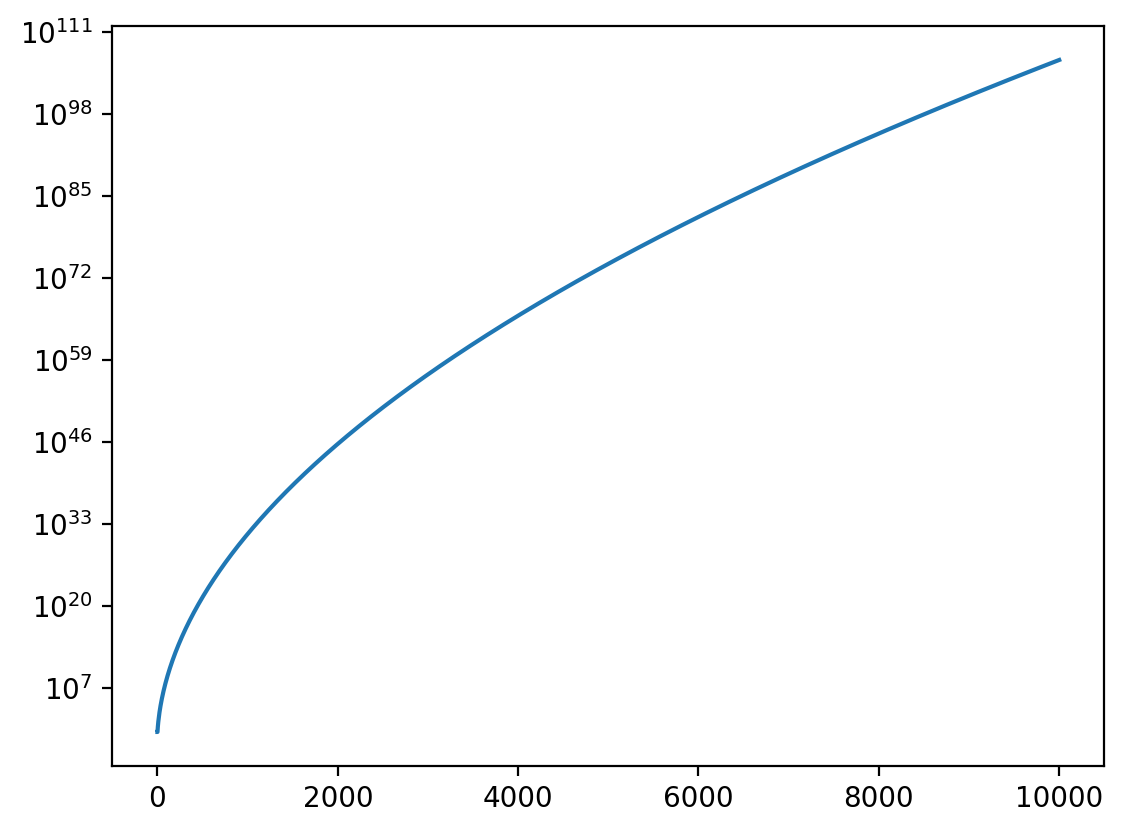

In [50]:
### ÉCRIVEZ ICI

def lpart(n):
    shifts = []
    k = 1
    while True:
        s1 = k * (3 * k - 1) // 2
        s2 = k * (3 * k + 1) // 2
        sign = 1 if k % 2 != 0 else -1
        
        if s1 > n:
            break
        shifts.append((sign, s1))
        
        if s2 > n:
            break
        shifts.append((sign, s2))
        
        k += 1
        
    p = [1]
    for i in range(1, n + 1):
        val = 0
        for sign, shift in shifts:
            if shift > i:
                break
            val += sign * p[i - shift]
        p.append(val)
        
    return p

y_vals = lpart(10000)
x_vals = range(10001)

plt.semilogy(x_vals, y_vals)
plt.show()


In [25]:
### EXÉCUTEZ-MOI - TEST

expected = 36167251325636293988820471890953695495016030339315650422081868605887952568754066420592310556052906916435144
assert (res:=lpart(10000)[-1]) == expected, f'obtenu : {res}, attendu : {expected}'
print('OK !')

OK !


Cela ressemble au graphique de la racine carrée, et puisque nous utilisons l'échelle logarithmique sur l'axe des ordonnées, il semble que $p(n)$ soit à peu près $\exp(c\sqrt{n})$ pour un certain $c$. [L'énoncé précis](https://en.wikipedia.org/wiki/Partition_function_(number_theory)#Approximation_formulas) est 
$$ p(n) \sim \frac1{4n\sqrt3}\, \exp \biggl(\pi\sqrt{\frac{2n}3}\biggr)$$
(provenant de certaines [symétries surprenantes de la fonction génératrice](https://fr.wikipedia.org/wiki/Fonction_%C3%AAta_de_Dedekind) $P(x)$).

Vérifions-le expérimentalement en traçant 
$$n\,p(n)\exp\biggl(-\pi\sqrt{\frac{2n}3}\biggr)$$
qui devrait, d'après cette formule, converger vers
$$\frac1{4\sqrt3}\approx 0.1443$$
indiqué par la ligne rouge en pointillés.


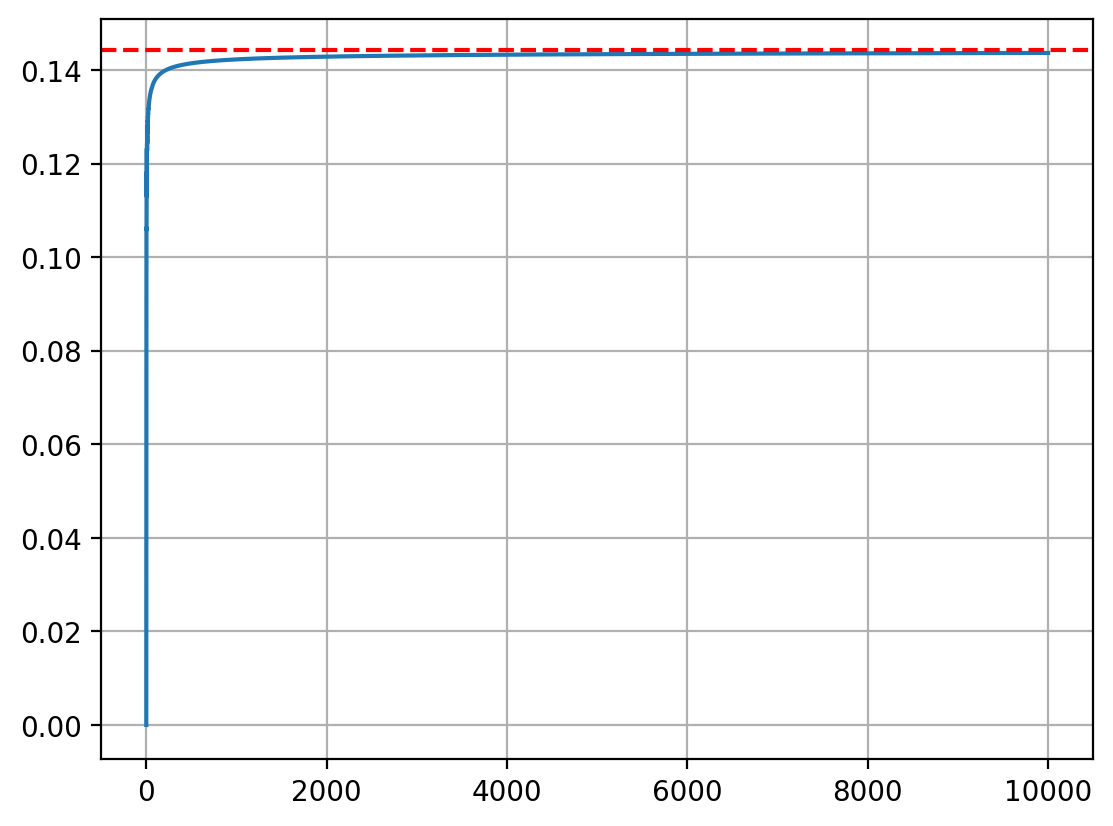

In [26]:
### EXÉCUTEZ-MOI

import numpy as np
ps = np.array(lpart(10000))
n = np.arange(10001)
plt.plot(n * ps * np.exp( -np.pi * np.sqrt(2*n/3)))
plt.axhline(1 / (4 * np.sqrt(3)), color='red', linestyle='--')
plt.grid()
plt.show()

## Alignement d'ADN (une excursion en bioinformatique)

Avant de regarder l'ADN, voici un problème avec presque la même solution. Au lieu de calculer « de combien de façons cela peut-il se produire ? », nous allons calculer « quelle est la meilleure façon dont cela peut se produire ? ». Ce n'est pas trop différent - nous devons just remplacer $+$ par $\max$ ou $\min$.

### Le retour du roi

Nous avons maintenant une tâche légèrement différente pour notre roi en déplacement. Il va toujours de $(0,0)$ à $(m,n)$. Mais maintenant, à chaque position $(k,l)$, il y a soit $1$ (elfe), $-1$ (orc), ou $0$ (personne). Il veut choisir son chemin de sorte que la somme des nombres qu'il rencontre sur son trajet soit la plus grande possible. Comment pouvons-nous trouver ce maximum ?

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :** On vous donne un tableau `c` en 2 dimensions de taille $N\times N$ contenant les nombres $+1$, $-1$, $0$ (`c[i,j]` sont définis pour $0\leq i,j <N$). Écrivez une fonction Python `maxking(m, n)` (où nous supposons que $m,n<N$) qui renvoie la somme maximale des `c[i,j]` que le roi peut rencontrer sur son trajet. Pour ce faire, trouvez d'abord une formule de récurrence calculant `maxking(m, n)` à partir de `maxking(m-1, n)`, `maxking(m, n-1)`, `maxking(m-1, n-1)`. 
</div>

**Conseils d'implémentation :**
1. Python a une fonction `max` pour trouver le maximum, qui vous aidera probablement. Implémentez votre fonction soit de manière récursive avec un décorateur `@cache`, soit en stockant les valeurs dans un tableau.
2. Votre formule de récurrence aura des cas particuliers, lorsque $m$ ou $n$ est 0. Vous pouvez les éviter en utilisant $-\infty$ comme certaines des valeurs. Vous pouvez obtenir $\infty$ avec `np.inf` (ou `float('inf')` ou `sp.oo` (un type différent, mais tout aussi bon à cet effet)).

Créons d'abord (et visualisons : les elfes sont verts et les orcs sont roses) le tableau `c`, avec $N=50$ :


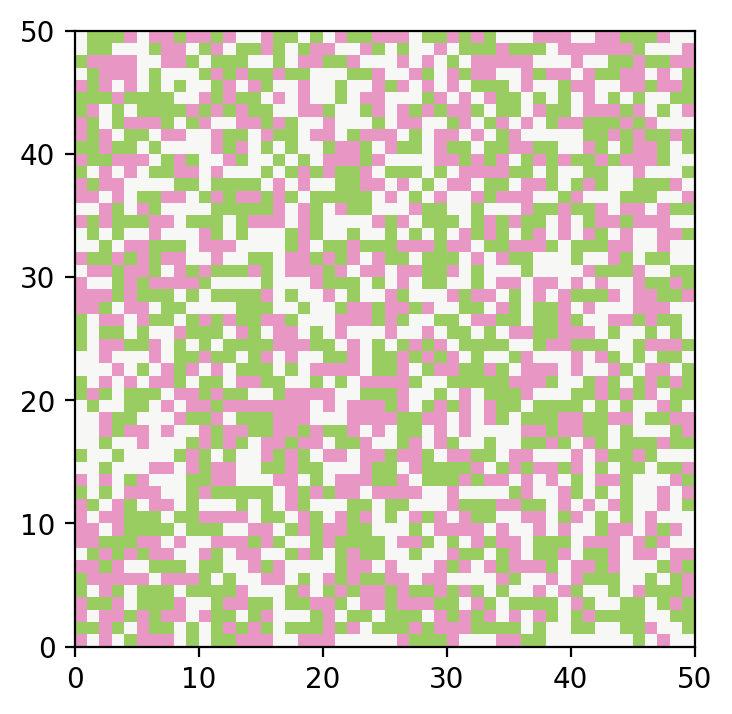

In [27]:
### EXÉCUTEZ-MOI

N = 50

# définit la graine aléatoire pour que tout le monde obtienne le même c
np.random.seed(42)
c = np.random.choice([1,0,-1], size=(N, N))

plt.figure(figsize=(4, 4))
plt.pcolormesh(c.T, cmap='PiYG', vmin=-2, vmax=2)
plt.show()

Maintenant, vous pouvez implémenter la fonction `maxking`.


In [51]:
### ÉCRIVEZ ICI

@cache
def maxking(m, n):
    if m < 0 or n < 0:
        return -np.inf
    if m == 0 and n == 0:
        return c[0, 0]
    
    return c[m, n] + max(
        maxking(m - 1, n),
        maxking(m, n - 1),
        maxking(m - 1, n - 1)
    )

In [29]:
### EXÉCUTEZ-MOI - TEST

assert (res:=maxking(49, 49)) == 63, f"attendu : 63, obtenu : {res}"
print("OK !")

OK !


C'est bien de connaître le meilleur score que le roi peut atteindre, mais ce serait encore mieux de voir un chemin avec ce score.

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :** Écrivez une fonction `maxking_path(m,n)` qui renvoie une paire `(score, path)`. Ici, `score` devrait être le meilleur score possible d'un chemin (c'est-à-dire `maxking(m,n)`) et `path` devrait être un chemin avec ce score, à savoir la liste $[(x_0,y_0), (x_1, y_1), \dots, (x_k, y_k)]$ des positions du roi le long de son chemin ($\,(x_0, y_0) = (0,0)$ et $(x_k, y_k)=(m,n)\,$).
</div>

**Conseils d'implémentation :**

1. Cette fonction devrait être une modification relativement petite de `maxking(m,n)`.
2. Python peut comparer deux tuples ou listes, en regardant les premiers éléments, puis, si nécessaire, les deuxièmes, etc. ; par exemple `(2,7) < (4,0)` et `(2,[1,3]) < (2,[2,2])`. La fonction `max` fonctionne aussi avec les tuples et les listes. Alternativement (la manière « correcte »™), utilisez l'argument optionnel `key` de `max`.
3. Pour étendre un chemin (sous forme de liste) par une nouvelle position `(m,n)`, utilisez `path + [(m,n)]` et non `path.append((m,n))` - vous voulez créer un nouvel objet, et non modifier l'ancien. 
4. Il peut y avoir plusieurs chemins avec le meilleur score. Nous en voulons juste un seul.


In [52]:
### ÉCRIVEZ ICI

@cache
def maxking_path(m, n):
    if m < 0 or n < 0:
        return -np.inf, []
    if m == 0 and n == 0:
        return c[0, 0], [(0, 0)]
        
    best_prev = max(
        maxking_path(m - 1, n),
        maxking_path(m, n - 1),
        maxking_path(m - 1, n - 1),
        key=lambda item: item[0]
    )
    
    return best_prev[0] + c[m, n], best_prev[1] + [(m, n)]

In [31]:
### EXÉCUTEZ-MOI - A TEST

score, path = maxking_path(49, 49)
assert score == sum(c[i,j] for i, j in path) == 63, " :( "
print('OK !')

OK !


Visualisons le chemin.


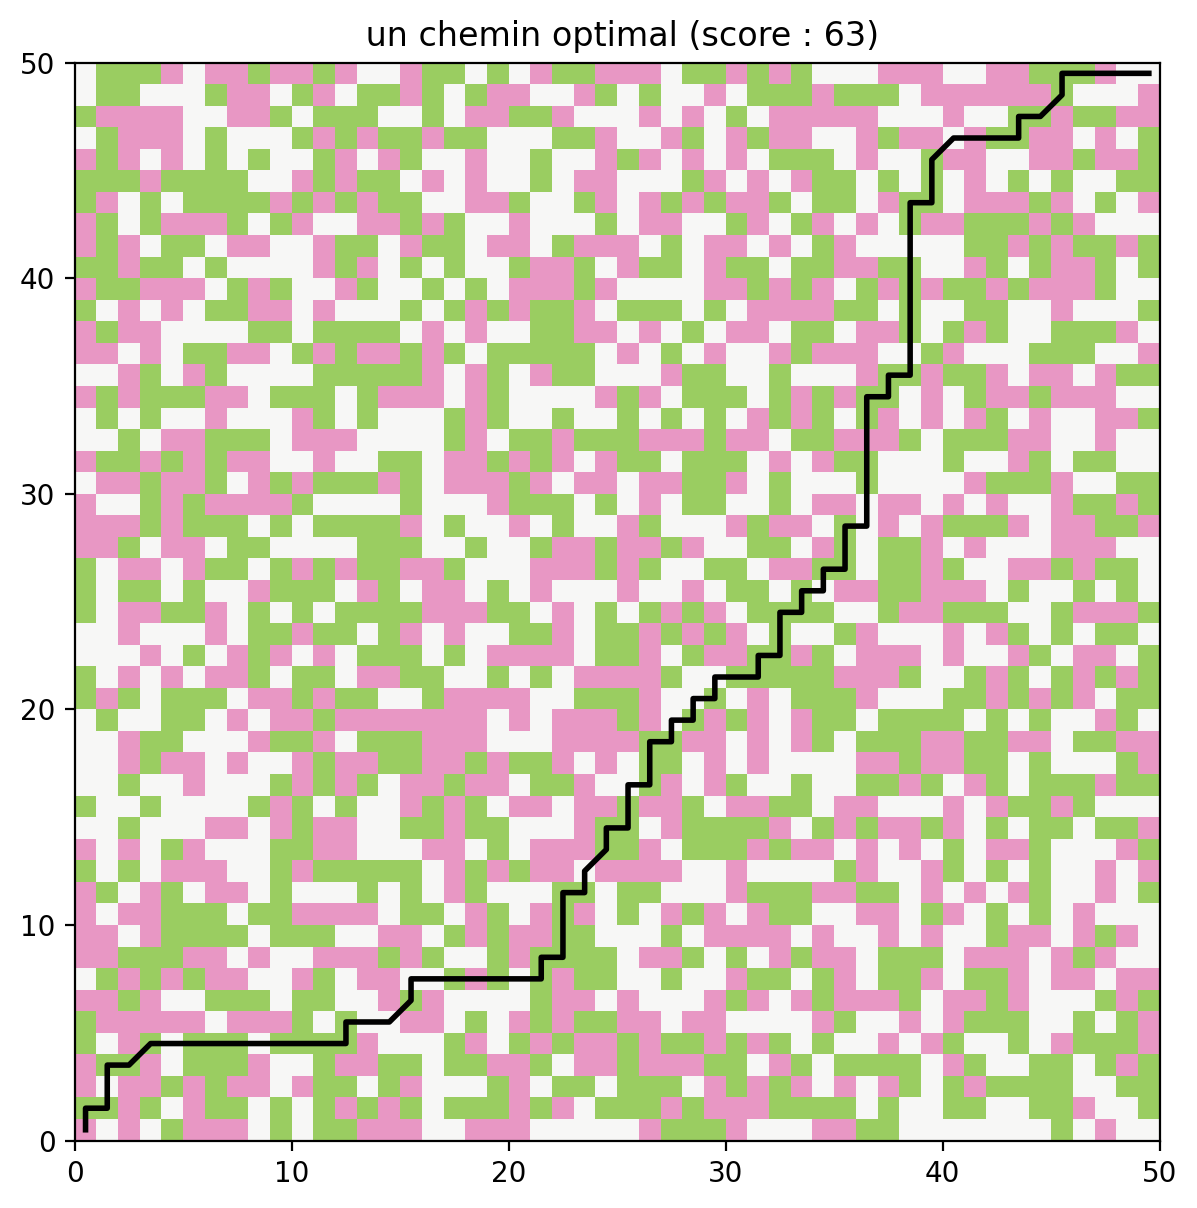

In [32]:
### EXÉCUTEZ-MOI

score, path = maxking_path(N-1, N-1)
plt.figure(figsize=(7, 7))
plt.title(f" un chemin optimal (score : {score})")
plt.pcolormesh(c.T, cmap='PiYG', vmin=-2, vmax=2) 
x_coords = [step[0] + 0.5 for step in path]
y_coords = [step[1] + 0.5 for step in path]
plt.plot(x_coords, y_coords, color='black',  linewidth=2)
plt.show()

### À quelle distance est la grenouille ?


Dans la cellule ci-dessous se trouvent les séquences d'ADN de divers organismes, codant pour une certaine protéine très importante ([cytochrome c](https://fr.wikipedia.org/wiki/Cytochrome_c)).




In [37]:
### EXÉCUTEZ-MOI

genes = {
    "human": 
        "ATGGGTGATGTTGAGAAAGGCAAGAAGATTTTTATTATGAAGTGTTCCCAGTGCCACACC"
        "GTTGAAAAGGGAGGCAAGCACAAGACTGGGCCAAATCTCCATGGTCTCTTTGGGCGGAAG"
        "ACAGGTCAGGCCCCTGGATACTCTTACACAGCCGCCAATAAGAACAAAGGCATCATCTGG"
        "GGAGAGGATACACTGATGGAGTATTTGGAGAATCCCAAGAAGTACATCCCTGGAACAAAA"
        "ATGATCTTTGTCGGCATTAAGAAGAAGGAAGAAAGGGCAGACTTAATAGCTTATCTCAAA"
        "AAAGCTACTAATGAGTAA",
    "mouse": 
        "ATGGGTGATGTTGAAAAAGGCAAGAAGATTTTTGTTCAGAAGTGTGCCCAGTGCCACACT"
        "GTGGAAAAGGGAGGCAAGCATAAGACTGGACCAAATCTCCACGGTCTGTTCGGGCGGAAG"
        "ACAGGTCAGGCCCCTGGATATTCTTACACAGCCGCCAATAAGAACAAAGGCATCACCTGG"
        "GGAGAGGATACCCTGATGGAGTATTTGGAGAATCCCAAAAAGTACATCCCTGGAACAAAA"
        "ATGATCTTCGTTGGCATTAAGAAGAAGGAAGAAAGGGCAGACCTAATAGCTTATCTCAAA"
        "AAAGCTACTAATGAGTAA",
    "frog": 
        "ATGGGTGATGCAGAGAAAGGCAAGAAGATTTTTATTCAAAAGTGTGCACAGTGCCACACC"
        "GTTGAAAAGACCGGCAAGCACAAGACTGGGCCAAATCTCTGGGGTCTCTTTGGGCGGAAG"
        "ACAGGTCAGGCCCCTGGATTTTCTTACACAGATGCCAATAAGAGCAAAGGCATCGTGTGG"
        "GGAGAGGATACACTGTTTGAGTATTTGGAGAATCCCAAGAAGTACATCCCTGGAACAAAA"
        "ATGATCTTTGCAGGCATTAAGAAGAAGAACGAAAGGCTCGACTTAATAGCTTATCTCAAA"
        "AAAAGCACTAGCGAGTAA",
    "fruit fly": 
        "ATGGGCGTTCCTGCTGGTGACGTGGAAAAAGGCAAGAAGATTTTTGTGCAGAAGTGTGCC"
        "GCCTGTCACACTGTCGAGGAGGGAGGCAAGCACAAGACTGGACCAAATCTCCATGGTCTC"
        "TTCGGGCGGAAGACAGGTCAGGCCTCCGGATACTCTTACACAGCCGCCAATAAGAACAAA"
        "GGCATCACCTGGGGAGAGGATACCCTGATGGAGTACTTGGAGAATCCCAAGAAGTACATC"
        "CCTGGAACAAAAATGATCTTCGCCGGCATTAAGAAGAAGGGAGAAAGGGCAGACCTAATT"
        "GCTTACCTCAAAAAGGCTACTAATGAGTAA",
    "yeast": 
        "ATGACTGAATTCAAGGCCGGTTCTGCTAAGAAAGGTGCTACACTTTTCAAGACTAGATGT"
        "CTACAATGCCACACCGTGGAAAAGGGTGGCCCACATAAGGTTGGTCCAAACTTGCATGGT"
        "ATCTTTGGCAGACACTCTGGTCAAGCTGAAGGGTATTCGTACACAGATGCCAATATCAAG"
        "AAAAACGTGTTGTGGGACGAAAATAACATGTCAGAGTACTTGACTAACCCAAAGAAATAT"
        "ATTCCTGGTACCAAGATGGCTTTCGGTGGGTTGAAGAAGGAAAAAGACAGAAACGACTTA"
        "ATTACCTACTTGAAAAAAGCCTGTGAGTAA",
    "plant": 
        "ATGGCATCCTTCGACGAGGCTCCACCGGGAAACCCCAAGGCAGGAGAGAAAATCTTCAAG"
        "ACCAAGTGCGCACAGTGCCACACCGTGGACAAGGGAGCCGGCCATAAGCAGGGCCCGAAC"
        "CTTAACGGCCTTTTCGGACGACAAAGCGGAACCACCCCGGGATACTCATACAGTGCCGCC"
        "AATAAGAACATGGCGGTCATCTGGGAAGAAAACACCCTCTATGACTACCTCTTAAACCCT"
        "AAAAAATACATCCCCGGAACCAAGATGGTCTTTCCGGGTCTGAAGAAGCCACAAGACAGA"
        "GCCGACCTAATCGCCTATCTCAAAAAGGCCACTTCCAGCTAA",
    "random noise": 
        "GTACTGACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTAC"
        "GTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTA"
        "CGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTG"
        "ACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGT"
        "ACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACGTACGTACGTGACG"
        "TACGTACGTGACGTACGTA"
}

print('Code du cytochrome c dans l\'ADN humain :', genes['human'])

Code du cytochrome c dans l'ADN humain : ATGGGTGATGTTGAGAAAGGCAAGAAGATTTTTATTATGAAGTGTTCCCAGTGCCACACCGTTGAAAAGGGAGGCAAGCACAAGACTGGGCCAAATCTCCATGGTCTCTTTGGGCGGAAGACAGGTCAGGCCCCTGGATACTCTTACACAGCCGCCAATAAGAACAAAGGCATCATCTGGGGAGAGGATACACTGATGGAGTATTTGGAGAATCCCAAGAAGTACATCCCTGGAACAAAAATGATCTTTGTCGGCATTAAGAAGAAGGAAGAAAGGGCAGACTTAATAGCTTATCTCAAAAAAGCTACTAATGAGTAA


Nous voulons comprendre à quelle distance ces organismes sont les uns des autres, génétiquement parlant. Une façon de mesurer la distance entre une grenouille et un humain est de calculer le nombre minimal de mutations nécessaires pour changer l'ADN de la grenouille en ADN humain. 
> Traditionnellement, le changement se fait avec un baiser, l'humain est un prince (plus tard un roi).

Par mutation, nous entendrons l'une de ces 3 modifications :
1. Une suppression de caractère, par exemple AT**T**AC → ATAC, ou **A**TTAC → TTAC
2. Une insertion de caractère, par exemple ATAC → AT**T**AC, ou TTAC → **A**TTAC
3. Un remplacement de caractère, par exemple ATTA**C** → ATTA**G**, ou A**T**TAC → A**A**TAC

Le nombre minimal de ces mutations nécessaires pour modifier une chaîne en une autre est appelé la _distance d'édition_, ou la [distance de Levenshtein](https://fr.wikipedia.org/wiki/Distance_de_Levenshtein), entre les deux chaînes.

> Comment pouvons-nous calculer la distance d'édition entre deux chaînes, disons 'ORANGE' et 'ARAGORN' ? Nous pouvons représenter une séquence de mutations en alignant les chaînes, avec quelques espaces  (correspondant à des suppressions ou des insertions) :
> ```
> ORANG-E-
> ARA-GORN
> ```
> Ici, nous avons 5 mutations : 2 insertions (O et N), 1 suppression (N), 2 remplacements (O→A, E→R).
>
> C'est l'une des manières optimales de transformer ORANGE en ARAGORN, c'est-à-dire que 5 est le nombre minimal de mutations. Mais cela signifie que si nous retirons la première colonne
> ```
> RANG-E-
> RA-GORN
> ```
> nous avons à nouveau une transformation optimale, cette fois de RANGE en RAGORN, par 4 mutations (si elle n'était pas optimale, nous pourrions en prendre une meilleure, rattacher la dernière colonne, et obtenir une meilleure transformation de ORANGE en ARAGORN).
>
> Mais cela nous donne un algorithme récursif : la première colonne de _n'importe quel_ alignement de ORANGE et ARAGORN est l'un de O-, -A, OA (dans ce cas, chacun d'eux est une mutation : -A est une insertion, O- une suppression, OA un remplacement), et donc
> $$\text{dist(ORANGE, ARAGORN)} = \min\bigl(1+\text{dist(RANGE, ARAGORN)},1+\text{dist(ORANGE, RAGORN)},1+\text{dist(RANGE, RAGORN)}\bigr)$$
>

La formule de récurrence que nous obtenons, écrite en syntaxe Python, est (en supposant que les chaînes `str1` et `str2` ne sont pas vides)
```python
dist(str1, str2) = min(1 + dist(str1[1:], str2), 1 + dist(str1, str2[1:]), penalty + dist(str1[1:], str2[1:]))
```
où `penalty` est 0 si les caractères de départ `str1[0]` et `str2[0]` sont les mêmes, et 1 sinon.

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :** Implémentez la fonction `dist(str1, str2)`. Si l'une des chaînes est vide, elle doit renvoyer la longueur de l'autre chaîne, et sinon utiliser la formule de récurrence. N'oubliez pas d'utiliser `@cache`. Trouvez la distance entre l'humain et la souris (`mouse`), l'humain et la grenouille (`frog`), et l'humain et la plante (`plant`).
</div>

> **Note technique sur les limites de récursivité :**
> Les séquences d'ADN que nous sommes sur le point de comparer ont une longueur d'environ 300 caractères. Cela signifie que votre fonction récursive `dist` s'appellera elle-même à une profondeur d'environ 600 fois. Python a un filet de sécurité intégré qui empêche les fonctions de s'appeler de manière récursive plus d'environ 1 000 fois (pour éviter les plantages de mémoire). 
>
> Nous sommes largement en dessous de cette limite ici, mais si vous essayiez de comparer des séquences d'ADN plus longues, cette approche récursive planterait avec une `RecursionError` ! Pour les séquences longues, les biologistes utilisent des versions non récursives (itératives) de cet algorithme.



In [ ]:
### ÉCRIVEZ ICI

@cache
def dist(str1, str2):
    if not str1:
        return len(str2)
    if not str2:
        return len(str1)
        
    penalty = 0 if str1[0] == str2[0] else 1
    
    return min(
        1 + dist(str1[1:], str2),
        1 + dist(str1, str2[1:]),
        penalty + dist(str1[1:], str2[1:])
    )

In [39]:
print(dist(genes['human'], genes['mouse']))
print(dist(genes['human'], genes['frog']))
print(dist(genes['human'], genes['plant']))

19
33
121


In [41]:
### EXÉCUTEZ-MOI - TEST

assert (res:=dist(genes['human'], genes['frog'])) == 33, f'attendu : 33, obtenu : {res}'
print('OK !')

OK !


Enfin, utilisons votre fonction pour visualiser toutes les distances.


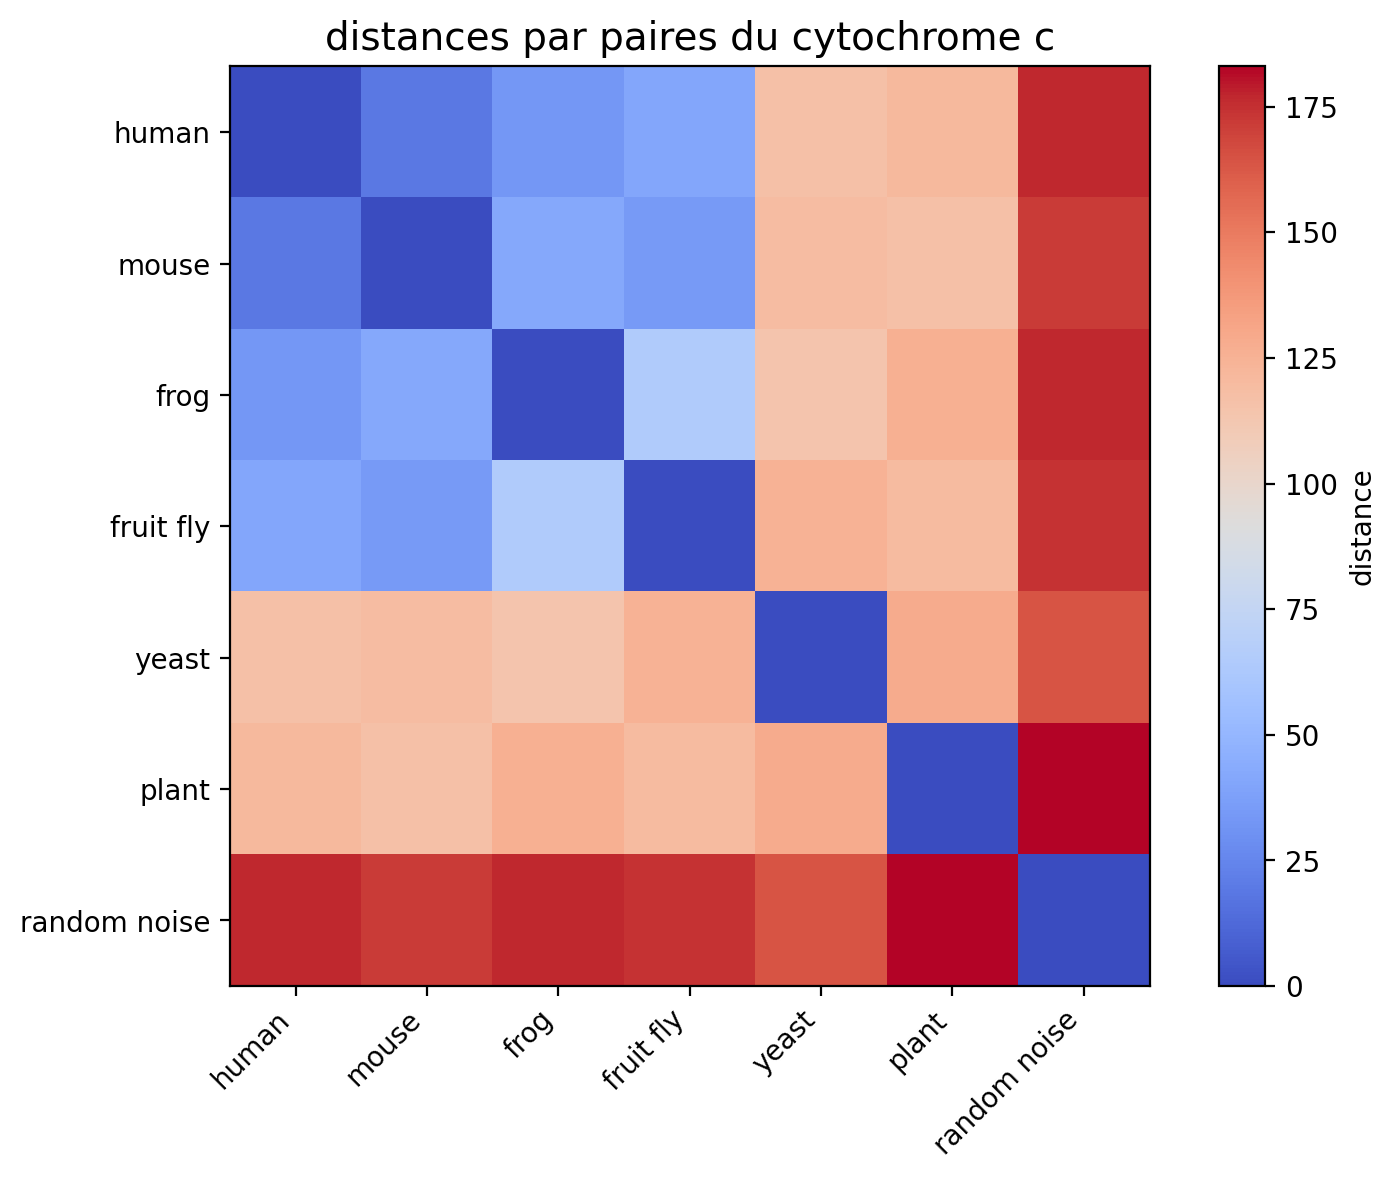

In [42]:
### EXÉCUTEZ-MOI

# 1. Extrait les noms et initialise une matrice NxN vide
names = list(genes.keys())
N = len(names)
score_matrix = np.zeros((N, N))

# 2. La boucle intelligente : on ne calcule que le triangle supérieur !
for i in range(N):
    for j in range(i, N): # Remarquez que j commence à i, et non à 0
        
        # Calcule le score une seule fois...
        score = dist(genes[names[i]], genes[names[j]])
        
        # ...et le sauvegarde dans les deux emplacements symétriques !
        score_matrix[i, j] = score
        score_matrix[j, i] = score

# 3. La visualisation
plt.figure(figsize=(8, 6))

im = plt.imshow(score_matrix, cmap='coolwarm') 

# Ajoute l'échelle de couleurs sur la droite
plt.colorbar(im, label='distance')

# Place les noms des espèces sur les axes X et Y
# rotation=45 incline les étiquettes X pour qu'elles ne se chevauchent pas
plt.xticks(ticks=range(N), labels=names, rotation=45, ha='right')
plt.yticks(ticks=range(N), labels=names)

plt.title("distances par paires du cytochrome c", fontsize=14)
plt.tight_layout() # Cela empêche les étiquettes inclinées d'être coupées
plt.show()

```